# 13 - E4 robustness degradations

**Question this notebook answers:** how much do the project's detectors degrade on the
ASVspoof 2019 logical access (LA) eval set under four realistic distribution shifts a
deployed detector would meet: lossy transcoding (MP3, Opus), additive background noise, and a
lossy sample-rate round trip? This notebook explains and demonstrates the test-set
generator for experiment E4; it does not score any detector.

**Scope:** ONE severity level per degradation type, applied test-time only to a fixed,
seeded, stratified 10,000-clip subset of the 2019 LA eval set (proportions match the full
eval set's label/attack_id mix):

| condition | what | why this level |
|---|---|---|
| `eval_mp3_32k` | MP3 (MPEG-1 Audio Layer III, libmp3lame), constant bit rate (CBR) 32 kbps | common lossy "voice memo forwarded over messaging app" bitrate |
| `eval_opus_16k` | Opus (libopus) 16 kbps | voice-over-IP (VoIP) call-quality bitrate; Opus runs its own resampling internally |
| `eval_noise_10db` | `noise/` from the MUSAN (Music, Speech, and Noise) corpus, mixed in at 10 dB signal-to-noise ratio (SNR) | audible-but-not-overwhelming background noise, the kind a phone mic actually picks up |
| `eval_resample_8k` | 16 -> 8 -> 16 kHz resample round trip | legacy telephony bandwidth (narrowband speech, no content above 4 kHz) |

Everything here is **test-time only**: no training data is degraded and no detector is
retrained on degraded audio. Scoring the degraded test sets is done by the A1/A2 runners on
the manifests this generator writes (`audio_df.data.degrade`, `scripts/make_degraded.py`).

Imports only from `audio_df.data.degrade` / `audio_df.data.manifests` / `audio_df.runtime.resources` and this
project's own scripts (`scripts/make_degraded.py`); no feature extraction or model code is
defined here.

In [1]:
# Work from the repo root, so config and manifest paths (all relative to it) resolve
# wherever the notebook is opened from (VS Code starts kernels in notebooks/).
import os
from pathlib import Path

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(REPO_ROOT)
print("working directory:", REPO_ROOT)

working directory: /Users/zuttome/LocalDocs/Learning/College/NUS/MTech-AIS/PS/GC2


In [2]:
import importlib.util
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from audio_df.features.audio import load_audio  # noqa: E402 (after the scripts/ path setup)
from audio_df.data.degrade import degrade  # noqa: E402

_spec = importlib.util.spec_from_file_location(
    "make_degraded", REPO_ROOT / "scripts" / "make_degraded.py"
)
make_degraded = importlib.util.module_from_spec(_spec)
sys.modules["make_degraded"] = make_degraded
_spec.loader.exec_module(make_degraded)

CONFIG_PATH = REPO_ROOT / "configs" / "e4_degradations.yaml"
cfg = make_degraded.load_config(CONFIG_PATH)
print("seed:", cfg["seed"])
print("subset n:", cfg["subset"]["n"], " clip_ids stored:", len(cfg["subset"]["clip_ids"]))
print("conditions:", list(cfg["conditions"].keys()))

/Users/zuttome/LocalDocs/Learning/College/NUS/MTech-AIS/PS/GC2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seed: 1337
subset n: 10000  clip_ids stored: 10000
conditions: ['eval_mp3_32k', 'eval_opus_16k', 'eval_noise_10db', 'eval_resample_8k']


## Subset proportions vs the full eval set

`audio_df.data.manifests.stratified_subset` allocates the 10,000 clips across `(label, attack_id)`
strata by the largest-remainder method, so the subset's class/attack mix should track the
full eval set's mix closely. **Mode:** if `data/manifests/eval.csv` exists (the real
ASVspoof 2019 LA eval manifest), this compares against it directly; otherwise a small
synthetic manifest stands in so this cell still runs.

**What the stored run shows (`mode: real`):** the subset matches the full eval mix to two
decimals: 1,032 bona fide clips (10.32 %, as in the full set) and 690 clips for each of
A07-A17 and 689 for A18 and A19 (6.90 % / 6.89 % against 6.90 % in the full set).

In [3]:
eval_manifest_path = REPO_ROOT / cfg["subset"]["source_manifest"]
if eval_manifest_path.exists():
    full_df = pd.read_csv(eval_manifest_path)
    mode = "real"
else:
    # Synthetic stand-in, same shape as the real manifest, so this cell is always reviewable.
    rows = []
    for i in range(200):
        rows.append(
            {
                "utt_id": f"SYN_{i:04d}",
                "label": "bonafide" if i < 30 else "spoof",
                "attack_id": "-" if i < 30 else f"A{7 + (i % 13):02d}",
            }
        )
    full_df = pd.DataFrame(rows)
    mode = "synthetic"
print("mode:", mode)

if mode == "real":
    sub_df = make_degraded.compute_subset(cfg, full_df)
else:
    # cfg["subset"]["clip_ids"] names real utt_ids that don't exist in our synthetic stand-in,
    # so recompute a fresh subset of the synthetic frame directly instead.
    from audio_df.data.manifests import stratified_subset

    sub_df = stratified_subset(full_df, n=60, strata=("label", "attack_id"), seed=cfg["seed"])

full_counts = full_df.groupby(["label", "attack_id"]).size()
sub_counts = sub_df.groupby(["label", "attack_id"]).size()
table = pd.DataFrame(
    {
        "full_n": full_counts,
        "full_pct": (full_counts / len(full_df) * 100).round(2),
        "subset_n": sub_counts,
        "subset_pct": (sub_counts / len(sub_df) * 100).round(2),
    }
).fillna(0)
table

mode: real


full_n  full_pct  subset_n  subset_pct
label    attack_id                                        
bonafide -            7355     10.32      1032       10.32
spoof    A07          4914      6.90       690        6.90
         A08          4914      6.90       690        6.90
         A09          4914      6.90       690        6.90
         A10          4914      6.90       690        6.90
         A11          4914      6.90       690        6.90
         A12          4914      6.90       690        6.90
         A13          4914      6.90       690        6.90
         A14          4914      6.90       690        6.90
         A15          4914      6.90       690        6.90
         A16          4914      6.90       690        6.90
         A17          4914      6.90       690        6.90
         A18          4914      6.90       689        6.89
         A19          4914      6.90       689        6.89

## One clip under all four conditions

Pick one bonafide clip from the subset and run it through every condition, then compare
spectrograms. This is cheap (one clip, four ffmpeg subprocess round trips at most), not a
full generation run. **Mode:** uses a real subset clip if the dataset is present locally,
else a synthesised 440 Hz tone standing in for "one clip" so the plotting code is still
exercised.

**What the stored run shows:** the real eval clip `LA_E_1001964` (6.61 s). MUSAN was not
present locally, so the noise panel uses **synthetic white noise** as a stand-in, not the
real noise bank; that panel shows the mixing step, not what real E4 noise looks like. Visible
effects in the spectrograms:

- **MP3 32 kbps:** a hard cut-off just above 7 kHz, and blocky holes in the 4-7 kHz region
  where the encoder discarded detail.
- **Opus 16 kbps:** the overall shape is kept but fine detail is smeared, and the silent gap
  near 3.4 s is filled with low-level codec noise.
- **Noise at 10 dB SNR (white-noise stand-in):** a flat noise floor across the whole band;
  speech structure stays visible mainly below about 1 kHz.
- **8 kHz round trip:** energy above about 4.5 kHz is strongly attenuated, while the band
  below 4 kHz looks like the clean clip.

using real clip: LA_E_1001964 duration_s= 6.6098125
MUSAN noise/ not found locally; using synthetic white noise as a stand-in (run scripts/get_musan.py to fetch the real corpus)


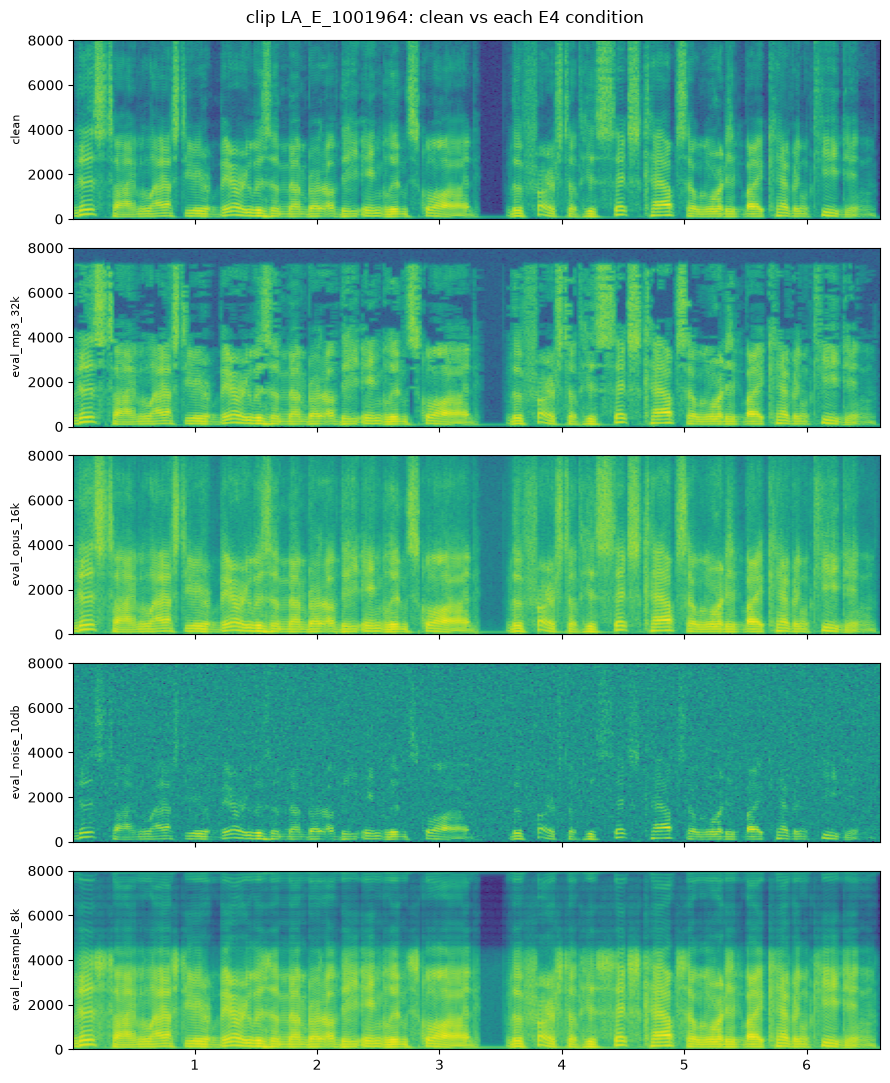

In [4]:
SR = 16000

if eval_manifest_path.exists() and len(cfg["subset"]["clip_ids"]):
    row = full_df[full_df["utt_id"] == cfg["subset"]["clip_ids"][0]].iloc[0]
    x, sr = load_audio(row["path"], target_sr=SR)
    clip_id = row["utt_id"]
    print("using real clip:", clip_id, "duration_s=", len(x) / sr)
else:
    t = np.arange(int(1.5 * SR)) / SR
    x = (
        0.3 * np.sin(2 * np.pi * 440 * t) + 0.02 * np.random.default_rng(0).normal(size=len(t))
    ).astype(np.float32)
    sr = SR
    clip_id = "SYNTHETIC_DEMO_CLIP"
    print("dataset not found locally; using a synthetic 440 Hz tone as the demo clip")

# The noise condition needs a noise bank; use MUSAN if present, else a synthetic noise bank
# so this cell still runs end-to-end when the MUSAN corpus has not been downloaded.
noise_dir = REPO_ROOT / cfg["conditions"]["eval_noise_10db"]["noise_dir"]
if noise_dir.is_dir():
    noise_bank = make_degraded.load_noise_bank(noise_dir)
else:
    rng = np.random.default_rng(1)
    noise_bank = [rng.normal(0, 1, size=SR * 3).astype(np.float32) for _ in range(3)]
    print(
        "MUSAN noise/ not found locally; using synthetic white noise as a stand-in "
        "(run scripts/get_musan.py to fetch the real corpus)"
    )

outputs = {"clean": x}
for name in cfg["conditions"]:
    outputs[name] = degrade(
        x, sr, name, cfg, seed=cfg["seed"], clip_id=clip_id, noise_bank=noise_bank
    )

fig, axes = plt.subplots(len(outputs), 1, figsize=(9, 2.2 * len(outputs)), sharex=True)
for ax, (name, sig) in zip(axes, outputs.items(), strict=True):
    ax.specgram(sig, Fs=sr, NFFT=512, noverlap=256)
    ax.set_ylabel(name, fontsize=8)
fig.suptitle(f"clip {clip_id}: clean vs each E4 condition")
plt.tight_layout()
plt.show()

## Timing

`scripts/make_degraded.py timing [--n 200]` times all four conditions on the first N subset
clips and extrapolates to the full 4 x 10,000-clip run (a **lower bound**, not a promise:
this is a fanless machine that throttles under sustained load). The cell below runs the same
`audio_df.runtime.resources.timing_run` machinery on 5 synthetic clips only to show the shape of the
output. Its numbers (median 0.97 ms per item, extrapolated 0.01 h for 40,000 items) are not a
real timing estimate; use the terminal command below for that.

In [5]:
from audio_df.data.degrade import resample_roundtrip
from audio_df.runtime.resources import format_timing, timing_run

rng = np.random.default_rng(2)
demo_clips = [(rng.normal(0, 0.3, size=SR // 2)).astype(np.float32) for _ in range(5)]


def _resample_one(sig):
    return resample_roundtrip(sig, sr=SR, mid_sr=8000)


timing = timing_run(_resample_one, demo_clips, n=len(demo_clips), total_items=40000)
print(format_timing(timing))

timed 5 items
  median 0.97 ms/item, mean 1.23 ms/item, p90 1.97 ms/item
  815.11 items/sec, peak RSS 492.6 MB
  peak MPS allocation 0.5 MB
  swap 2.484560546875 GB -> 2.484560546875 GB, pressure 1 -> 1
  EXTRAPOLATED (not measured) for 40000 items: 0.01 h — a fanless machine throttles under sustained load, so a real full run will likely take longer than this.


## Exact terminal commands

Run these from a terminal; the notebook does not run them.

```bash
# 1. Fetch MUSAN's noise/ subset (11 GB tarball, ~1 GB kept). Dry-run first:
uv run python scripts/get_musan.py --dry-run
uv run python scripts/get_musan.py

# 2. Re-verify the subset clip list matches configs/e4_degradations.yaml (should already
#    match -- it was generated once, deterministically, from the real eval manifest):
uv run python scripts/make_degraded.py subset --verify

# 3. Time all four conditions on 200 clips before committing to the full run:
caffeinate -i uv run python scripts/make_degraded.py timing --n 200

# 4. Generate. caffeinate -i keeps the machine awake without forcing the display on;
#    resumable if interrupted (partial progress is never lost past the current chunk):
caffeinate -i uv run python scripts/make_degraded.py generate
# ...if interrupted, or if it exits 3 (MemoryPressureExit):
caffeinate -i uv run python scripts/make_degraded.py generate --resume

# 5. Spot-check the outputs:
uv run python scripts/make_degraded.py verify
```

**Disk/time estimates** (printed for real by step 3's `timing` command, and written to
`data/cache/timing/e4.json`): FLAC-encoded 16 kHz mono clips at ASVspoof 2019 LA's average
eval-clip duration (a few seconds) run roughly 60-150 KB each; four conditions x ~10,000 clips is on
the order of a few GB total (`scripts/make_degraded.py`'s disk-estimate helper uses a
150 KB/clip conservative fallback when no timing run has been recorded yet, so it never
under-estimates). Wall time is dominated by the two codec conditions (ffmpeg subprocess
round trips); `noise` and `resample` are pure Python/`scipy` and much faster per clip.

## What comes next

Once `generate` has produced `data/manifests/eval_mp3_32k.csv`, `eval_opus_16k.csv`,
`eval_noise_10db.csv`, `eval_resample_8k.csv` (the manifest filename is exactly
`<condition_name>.csv`; every condition name already starts with `eval_`) and
`eval_clean10k.csv` (the clean reference: same clips, original paths), the existing
raw-trained detectors score these five test sets the same way they score the ordinary eval
set. Thresholds still come from dev, never from any of these. The `score` command requires `--model-from`, `--exp` and `--silence-mode`; fill in the raw-trained run
directories:

```bash
TESTSETS=eval_clean10k,eval_mp3_32k,eval_opus_16k,eval_noise_10db,eval_resample_8k

# A1 (LFCC-B02 + GMM)
uv run adf --config configs/a1_lfcc_gmm.yaml score \
    --model-from runs/<A1 raw run> --exp e4 --silence-mode raw --testsets $TESTSETS

# A2 (frozen SSL backbone + learned head): extract the pooled cache, then score
uv run adf --config configs/a2_wavlm_base_plus.yaml prepare --testsets $TESTSETS --silence-mode raw
uv run adf --config configs/a2_wavlm_base_plus.yaml score \
    --model-from runs/<A2 raw run> --exp e4 --silence-mode raw --testsets $TESTSETS

# Then build the tables, including E4 (per-condition EER/minDCF next to the clean10k reference):
uv run python scripts/make_tables.py
```

Here LFCC is linear-frequency cepstral coefficients, GMM a Gaussian mixture model, SSL
self-supervised learning, EER the equal error rate and minDCF the minimum normalised
detection cost function. This notebook's job ends here: the generator is explained and
demonstrated; scoring under degradation is done by the A1/A2 pipelines, and
`scripts/make_tables.py` turns those scores into the E4 comparison table.